# Retail Sales & Profit Intelligence Studio
**Business Intelligence and Analytics — Mini Project (Year 3, Sem V, Computer Engineering)**

Dataset: *Sample – Superstore* (official Tableau sample data, fictitious US & Canada retailer, 2023–2026)

**Contents**
1. Introduction
2. Data Collection / Data Description
3. Data Pre-processing
4. Mining Models / Analytics (KPIs, Returns, Regression, Classification, Clustering, Forecasting)
5. Results
6. Visualization (Charts / Plots)
7. Conclusion

## 1. Introduction

Retail businesses record thousands of order lines every year, but raw transactions do not tell managers *where* money is made or lost.
This project builds an end-to-end Business Intelligence workflow on the Superstore retail dataset:

* **Collect** and describe the transaction data.
* **Clean, merge and transform** it (column names, dates, postal codes, duplicates, joining the Returns and People sheets, derived fields).
* **Analyse** it with descriptive KPIs, a returns analysis and data-mining models:
  * **Regression** – predict the profit of an order line.
  * **Classification** – predict whether an order line will make a loss.
  * **Clustering** – group customers using RFM (Recency, Frequency, Monetary).
  * **Forecasting** – predict monthly sales.
* **Visualize** sales, profit, discount, customer and regional patterns.
* Present the results in a simple **black-and-white GUI with colour charts** (`app.py`, built with Streamlit).

**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn, scikit-learn, Streamlit, Plotly.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

# ---- Colour chart style (uses Poppins if it is installed) ----
FONT = "Poppins" if any("Poppins" in f.name for f in font_manager.fontManager.ttflist) else "DejaVu Sans"
PAL = ["#2E86AB", "#F18F01", "#C73E1D", "#3B8B5A", "#7B4B94", "#E2B13C"]   # blue, orange, red, green, purple, gold
POS, NEG = "#3B8B5A", "#C73E1D"                                            # profit = green, loss = red
sns.set_theme(style="whitegrid", palette=PAL, font=FONT)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titleweight": "bold", "figure.dpi": 100})
pd.set_option("display.float_format", "{:,.2f}".format)
print("Chart font:", FONT)

Chart font: DejaVu Sans


## 2. Data Collection / Data Description

**Source:** Tableau Public sample data – *Superstore Sales* (https://public.tableau.com/app/learn/sample-data).
The workbook `data/superstore.xls` has three sheets for a fictitious company selling in the **United States and Canada**:

* **Orders** – one row per **order line** (an order can have several lines)
* **Returns** – Order IDs that were returned
* **People** – the regional manager of each region

| Column | Meaning |
|---|---|
| Row ID | Line identifier |
| Order ID | Order identifier (repeats across lines) |
| Order Date / Ship Date | When the order was placed / shipped |
| Ship Mode | Shipping service |
| Customer ID / Customer Name / Segment | Customer and segment (Consumer, Corporate, Home Office) |
| Country/Region / City / State/Province / Postal Code / Region | Location (US and Canada) |
| Product ID / Category / Sub-Category / Product Name | Product hierarchy |
| Sales | Sales value of the line (USD) |
| Quantity | Units |
| Discount | Discount **rate** (0 – 0.8) |
| Profit | Profit or loss of the line (USD, can be negative) |

| Sheet | Columns |
|---|---|
| Returns | Order ID, Returned (Yes) |
| People | Regional Manager, Region |

In [2]:
DATA_PATH = "data/superstore.xls"
sheets = pd.read_excel(DATA_PATH, sheet_name=None, dtype={"Postal Code": str})
df_raw, returns, people = sheets["Orders"], sheets["Returns"], sheets["People"]
for name, d in sheets.items():
    print(f"{name:8s}: {d.shape[0]:,} rows x {d.shape[1]} columns")
df_raw.head()

Orders  : 10,194 rows x 21 columns
People  : 4 rows x 2 columns
Returns : 296 rows x 2 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.45,2,0.20,5.55
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.54,2,0.80,-5.49
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.78,3,0.20,4.27
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.74,3,0.20,-64.77
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.54,3,0.20,4.88


In [3]:
# Column summary: data type, non-null count and number of unique values
pd.DataFrame({"dtype": df_raw.dtypes.astype(str),
              "non_null": df_raw.notna().sum(),
              "unique": df_raw.nunique()})

,dtype,non_null,unique
Row ID,int64,10194,10194
Order ID,str,10194,5111
Order Date,datetime64[us],10194,1242
Ship Date,datetime64[us],10194,1338
Ship Mode,str,10194,4
Customer ID,str,10194,804
Customer Name,str,10194,800
Segment,str,10194,3
Country/Region,str,10194,2
City,str,10194,542


In [4]:
# Statistical summary of the numeric measures
df_raw[["Sales", "Quantity", "Discount", "Profit"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Sales,"10,194.00",228.23,619.91,0.44,17.22,53.91,209.50,"22,638.48"
Quantity,"10,194.00",3.79,2.23,1.00,2.00,3.00,5.00,14.00
Discount,"10,194.00",0.16,0.21,0.00,0.00,0.20,0.20,0.80
Profit,"10,194.00",28.67,232.47,"-6,599.98",1.76,8.69,29.30,"8,399.98"


In [5]:
for col in ["Country/Region", "Segment", "Region", "Category", "Ship Mode"]:
    print(f"\n{col}:\n", df_raw[col].value_counts().to_string())
print("\nDistinct orders   :", df_raw["Order ID"].nunique())
print("Distinct customers:", df_raw["Customer ID"].nunique())
print("Distinct products :", df_raw["Product ID"].nunique())
print("Returned orders   :", returns["Order ID"].nunique())


Country/Region:
 Country/Region
United States    9994
Canada            200

Segment:
 Segment
Consumer       5281
Corporate      3090
Home Office    1823

Region:
 Region
West       3253
East       2986
Central    2335
South      1620

Category:
 Category
Office Supplies    6128
Furniture          2201
Technology         1865

Ship Mode:
 Ship Mode
Standard Class    6120
Second Class      1979
First Class       1548
Same Day           547

Distinct orders   : 5111
Distinct customers: 804
Distinct products : 1862
Returned orders   : 296


In [6]:
display(returns.head())
display(people)

,Order ID,Returned
0,US-2023-100762,Yes
1,US-2023-100867,Yes
2,US-2023-102652,Yes
3,US-2023-103373,Yes
4,US-2023-103744,Yes


,Regional Manager,Region
0,Sadie Pawthorne,West
1,Chuck Magee,East
2,Roxanne Rodriguez,Central
3,Fred Suzuki,South


## 3. Data Pre-processing

Steps performed (the raw data is kept unchanged in `df_raw`; all changes go to `df`):
1. Standardise column names and check missing values
2. Duplicate check
3. Data types: dates as datetime; `Postal Code` as text, restoring the leading zero that Excel dropped from US ZIP codes
4. Validity checks (ship date after order date, positive sales/quantity, discount between 0 and 1)
5. Outlier **flagging** with the IQR rule (rows are *not* deleted – large sales and negative profits are real business cases)
6. Data integration: join the **Returns** and **People** sheets onto the orders
7. Feature engineering: year, month, quarter, shipping days, profit margin, discount band, loss flag

In [7]:
# 1. Standardise column names, then check missing values
df = df_raw.rename(columns={"Country/Region": "Country", "State/Province": "State"}).copy()

missing = pd.DataFrame({"missing": df.isna().sum(), "missing_%": df.isna().mean() * 100})
print("Total missing values:", int(missing["missing"].sum()))
missing[missing["missing"] > 0] if missing["missing"].sum() else missing.head(0)

Total missing values: 0


,missing,missing_%


In [8]:
# 2. Duplicates
print("Fully duplicated rows            :", df.duplicated().sum())
print("Duplicates ignoring Row ID        :", df.drop(columns="Row ID").duplicated().sum())
# Rows identical in every field except Row ID are treated as accidental duplicates and removed
before = len(df)
df = df.loc[~df.drop(columns="Row ID").duplicated()].copy()
print("Rows removed:", before - len(df))

Fully duplicated rows            : 0
Duplicates ignoring Row ID        : 2
Rows removed: 2


In [9]:
# 3. Data types
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])
us = df["Country"] == "United States"
print("US ZIP codes missing a leading zero:", (us & (df["Postal Code"].str.len() < 5)).sum())
df.loc[us, "Postal Code"] = df.loc[us, "Postal Code"].str.zfill(5)
print("Order date range:", df["Order Date"].min().date(), "to", df["Order Date"].max().date())
df.dtypes

US ZIP codes missing a leading zero: 438
Order date range: 2023-01-03 to 2026-12-30


Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code                 str
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

In [10]:
# 4. Validity checks
checks = {
    "Ship Date before Order Date": (df["Ship Date"] < df["Order Date"]).sum(),
    "Sales <= 0": (df["Sales"] <= 0).sum(),
    "Quantity <= 0": (df["Quantity"] <= 0).sum(),
    "Discount outside 0-1": (~df["Discount"].between(0, 1)).sum(),
    "Negative profit (kept, valid losses)": (df["Profit"] < 0).sum(),
}
pd.Series(checks, name="rows").to_frame()

,rows
Ship Date before Order Date,0
Sales <= 0,0
Quantity <= 0,0
Discount outside 0-1,0
"Negative profit (kept, valid losses)",1900


In [11]:
# 5. Outlier flags using IQR (flag only, no deletion)
def iqr_flag(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

df["Sales Outlier"] = iqr_flag(df["Sales"])
df["Profit Outlier"] = iqr_flag(df["Profit"])
print("Sales outliers flagged :", df["Sales Outlier"].sum())
print("Profit outliers flagged:", df["Profit Outlier"].sum())

Sales outliers flagged : 1183
Profit outliers flagged: 1913


In [12]:
# 6. Data integration: returns (order level) and regional managers
df = df.merge(returns.drop_duplicates("Order ID"), on="Order ID", how="left")
df["Returned"] = df["Returned"].fillna("No")
df["Is Returned"] = (df["Returned"] == "Yes").astype(int)
df = df.merge(people, on="Region", how="left")
print("Order lines in returned orders:", df["Is Returned"].sum())
print("Returned orders               :", df.loc[df["Is Returned"] == 1, "Order ID"].nunique())
df[["Order ID", "Region", "Regional Manager", "Returned"]].head()

Order lines in returned orders: 800
Returned orders               : 296


,Order ID,Region,Regional Manager,Returned
0,US-2023-103800,Central,Roxanne Rodriguez,No
1,US-2023-112326,Central,Roxanne Rodriguez,No
2,US-2023-112326,Central,Roxanne Rodriguez,No
3,US-2023-112326,Central,Roxanne Rodriguez,No
4,US-2023-141817,East,Chuck Magee,No


In [13]:
# 7. Feature engineering
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Quarter"] = df["Order Date"].dt.quarter
df["Year-Month"] = df["Order Date"].dt.to_period("M").astype(str)
df["Ship Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Profit Margin %"] = np.where(df["Sales"] != 0, df["Profit"] / df["Sales"] * 100, np.nan)
df["Discount Band"] = pd.cut(df["Discount"], bins=[-0.01, 0, 0.2, 0.4, 1.0],
                             labels=["No discount", "1-20%", "21-40%", "41-80%"])
df["Is Loss"] = (df["Profit"] < 0).astype(int)
df["Sales x Discount"] = df["Sales"] * df["Discount"]   # discount amount in USD

print("Raw shape    :", df_raw.shape)
print("Cleaned shape:", df.shape)
df.to_csv("data/superstore_cleaned.csv", index=False)
print("Saved -> data/superstore_cleaned.csv")
df.head()

Raw shape    : (10194, 21)
Cleaned shape: (10192, 35)
Saved -> data/superstore_cleaned.csv


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Regional Manager,Year,Month,Quarter,Year-Month,Ship Days,Profit Margin %,Discount Band,Is Loss,Sales x Discount
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,Roxanne Rodriguez,2023,1,1,2023-01,4,33.75,1-20%,0,3.29
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Roxanne Rodriguez,2023,1,1,2023-01,4,-155.00,41-80%,1,2.83
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Roxanne Rodriguez,2023,1,1,2023-01,4,36.25,1-20%,0,2.36
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Roxanne Rodriguez,2023,1,1,2023-01,4,-23.75,1-20%,1,54.55
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,Chuck Magee,2023,1,1,2023-01,7,25.00,1-20%,0,3.91


## 4. Mining Models / Analytics

### 4.1 Descriptive analytics – Key Performance Indicators
* Total Sales = Σ Sales, Total Profit = Σ Profit
* Orders = number of **distinct** Order IDs (not rows)
* Profit Margin = Σ Profit / Σ Sales × 100
* Average Order Value (AOV) = Σ Sales / distinct orders

In [14]:
def kpis(d):
    sales, profit, orders = d["Sales"].sum(), d["Profit"].sum(), d["Order ID"].nunique()
    return {"Total Sales ($)": sales, "Total Profit ($)": profit, "Orders": orders,
            "Units Sold": d["Quantity"].sum(), "Customers": d["Customer ID"].nunique(),
            "Profit Margin (%)": profit / sales * 100 if sales else np.nan,
            "Avg Order Value ($)": sales / orders if orders else np.nan,
            "Return Rate (% of orders)": d.loc[d["Is Returned"] == 1, "Order ID"].nunique() / orders * 100 if orders else np.nan,
            "Avg Ship Days": d["Ship Days"].mean()}

pd.Series(kpis(df)).to_frame("Value")

,Value
Total Sales ($),"2,326,153.86"
Total Profit ($),"292,273.46"
Orders,"5,111.00"
Units Sold,"38,644.00"
Customers,804.00
Profit Margin (%),12.56
Avg Order Value ($),455.13
Return Rate (% of orders),5.79
Avg Ship Days,3.96


In [15]:
# Year-wise performance
yearly = df.groupby("Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"))
yearly["Margin %"] = yearly["Profit"] / yearly["Sales"] * 100
yearly["Sales Growth %"] = yearly["Sales"].pct_change() * 100
yearly

,Sales,Profit,Orders,Margin %,Sales Growth %
Year,,,,,
2023,"493,659.72","51,660.94",995,10.46,NaN
2024,"472,993.03","62,020.97",1053,13.11,-4.19
2025,"613,933.58","82,665.20",1340,13.46,29.80
2026,"745,567.53","95,926.35",1723,12.87,21.44


In [16]:
# Category / Region performance
def perf(by):
    g = df.groupby(by).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                           Orders=("Order ID", "nunique"), Units=("Quantity", "sum"))
    g["Margin %"] = g["Profit"] / g["Sales"] * 100
    return g.sort_values("Sales", ascending=False)

display(perf("Category"))
display(perf("Region"))
display(perf("Segment"))

,Sales,Profit,Orders,Units,Margin %
Category,,,,,
Technology,"839,893.28","146,543.38",1560,7017,17.45
Furniture,"754,367.27","19,706.64",1819,8359,2.61
Office Supplies,"731,893.31","126,023.44",3812,23268,17.22


,Sales,Profit,Orders,Units,Margin %
Region,,,,,
West,"739,813.61","110,798.82",1635,12466,14.98
East,"691,447.68","94,859.90",1475,11149,13.72
Central,"503,170.67","39,865.31",1179,8820,7.92
South,"391,721.91","46,749.43",822,6209,11.93


,Sales,Profit,Orders,Units,Margin %
Segment,,,,,
Consumer,"1,170,659.79","136,371.45",2628,19844,11.65
Corporate,"715,707.01","94,214.23",1552,11890,13.16
Home Office,"439,787.06","61,687.79",931,6910,14.03


In [17]:
# Loss-making products (aggregate profit < 0)
prod = df.groupby("Product Name").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                                      Quantity=("Quantity", "sum"), Avg_Discount=("Discount", "mean"))
loss_products = prod[prod["Profit"] < 0].sort_values("Profit")
print("Loss-making products:", len(loss_products), "of", len(prod))
loss_products.head(10)

Loss-making products: 302 of 1849


,Sales,Profit,Quantity,Avg_Discount
Product Name,,,,
Cubify CubeX 3D Printer Double Head Print,"11,099.96","-8,879.97",9,0.53
Lexmark MX611dhe Monochrome Laser Printer,"16,829.90","-4,589.97",18,0.40
Cubify CubeX 3D Printer Triple Head Print,"7,999.98","-3,839.99",4,0.50
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,"9,917.64","-2,876.12",27,0.28
Bush Advantage Collection Racetrack Conference Table,"9,544.72","-1,934.40",33,0.35
GBC DocuBind P400 Electric Binding System,"17,965.07","-1,878.17",27,0.45
Cisco TelePresence System EX90 Videoconferencing Unit,"22,638.48","-1,811.08",6,0.50
Martin Yale Chadless Opener Electric Letter Opener,"16,656.20","-1,299.18",22,0.10
Balt Solid Wood Round Tables,"6,518.75","-1,201.06",19,0.20


### 4.2 Returns analysis
Return rate = share of **order lines** that belong to a returned order. (Returns are recorded per order, not per product.)

In [18]:
def return_rate(by):
    g = df.groupby(by, observed=True).agg(Lines=("Is Returned", "size"), Returned_Lines=("Is Returned", "sum"))
    g["Return Rate %"] = g["Returned_Lines"] / g["Lines"] * 100
    return g.sort_values("Return Rate %", ascending=False)

display(return_rate("Category"))
display(return_rate(["Region", "Regional Manager"]))
display(return_rate("Discount Band"))

,Lines,Returned_Lines,Return Rate %
Category,,,
Technology,1865,156,8.36
Furniture,2199,171,7.78
Office Supplies,6128,473,7.72


,,Lines,Returned_Lines,Return Rate %
Region,Regional Manager,,,
West,Sadie Pawthorne,3253,490,15.06
East,Chuck Magee,2984,149,4.99
South,Fred Suzuki,1620,69,4.26
Central,Roxanne Rodriguez,2335,92,3.94


,Lines,Returned_Lines,Return Rate %
Discount Band,,,
No discount,4924,401,8.14
1-20%,3854,310,8.04
41-80%,951,63,6.62
21-40%,463,26,5.62


### 4.3 Regression – Predicting the Profit of an order line
**Target:** `Profit`  **Features:** Sales, Quantity, Discount, Sales x Discount (discount amount), Category, Sub-Category, Region, Segment, Ship Mode
Models: **Linear Regression** (baseline) and **Random Forest Regressor**. 80/20 train-test split, plus 5-fold cross-validated R²
(profit has a few extreme values, so a single split can be misleading).

In [19]:
num_feats = ["Sales", "Quantity", "Discount", "Sales x Discount"]
cat_feats = ["Category", "Sub-Category", "Region", "Segment", "Ship Mode"]
X = df[num_feats + cat_feats]

pre = ColumnTransformer([("num", StandardScaler(), num_feats),
                         ("cat", OneHotEncoder(handle_unknown="ignore"), cat_feats)])

y_reg = df["Profit"]
Xtr, Xte, ytr, yte = train_test_split(X, y_reg, test_size=0.2, random_state=42)

reg_models = {"Linear Regression": LinearRegression(),
              "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)}
reg_results, reg_preds = [], {}
for name, model in reg_models.items():
    pipe = Pipeline([("pre", pre), ("model", model)]).fit(Xtr, ytr)
    p = pipe.predict(Xte)
    reg_preds[name] = p
    reg_models[name] = pipe
    cv_r2 = cross_val_score(pipe, X, y_reg, cv=KFold(5, shuffle=True, random_state=42), scoring="r2").mean()
    reg_results.append({"Model": name, "R2 (test)": r2_score(yte, p), "R2 (5-fold CV)": cv_r2,
                        "MAE ($)": mean_absolute_error(yte, p),
                        "RMSE ($)": np.sqrt(mean_squared_error(yte, p))})
reg_results = pd.DataFrame(reg_results).set_index("Model")
reg_results

,R2 (test),R2 (5-fold CV),MAE ($),RMSE ($)
Model,,,,
Linear Regression,0.80,0.63,35.45,103.63
Random Forest,0.67,0.59,19.54,131.38


In [20]:
# Feature importance from the Random Forest
rf = reg_models["Random Forest"]
names = rf.named_steps["pre"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names)
imp.index = imp.index.str.replace("num__", "").str.replace("cat__", "")
imp.sort_values(ascending=False).head(10).to_frame("Importance")

,Importance
Sales,0.50
Sales x Discount,0.29
Discount,0.07
Quantity,0.02
Sub-Category_Copiers,0.01
Sub-Category_Supplies,0.01
Sub-Category_Binders,0.01
Region_East,0.01
Sub-Category_Machines,0.01
Region_West,0.01


### 4.4 Classification – Will an order line make a loss?
**Target:** `Is Loss` (1 if Profit < 0)  **Features:** same as regression.
Models: **Logistic Regression** and **Decision Tree** (max depth 5). Stratified 80/20 split.

In [21]:
y_clf = df["Is Loss"]
print("Class balance:\n", y_clf.value_counts(normalize=True).rename({0: "Profit/Break-even", 1: "Loss"}))
Xtr, Xte, ytr, yte = train_test_split(X, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

clf_models = {"Logistic Regression": LogisticRegression(max_iter=1000),
              "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42)}
clf_results, clf_preds = [], {}
for name, model in clf_models.items():
    pipe = Pipeline([("pre", pre), ("model", model)]).fit(Xtr, ytr)
    p = pipe.predict(Xte)
    clf_preds[name] = p
    clf_models[name] = pipe
    clf_results.append({"Model": name, "Accuracy": accuracy_score(yte, p),
                        "Precision": precision_score(yte, p), "Recall": recall_score(yte, p),
                        "F1": f1_score(yte, p)})
clf_results = pd.DataFrame(clf_results).set_index("Model")
clf_results

Class balance:
 Is Loss
Profit/Break-even   0.81
Loss                0.19
Name: proportion, dtype: float64


,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.94,0.95,0.72,0.82
Decision Tree,0.95,0.96,0.76,0.85


In [22]:
print(classification_report(yte, clf_preds["Decision Tree"], target_names=["Profit", "Loss"]))

              precision    recall  f1-score   support

      Profit       0.95      0.99      0.97      1659
        Loss       0.96      0.76      0.85       380

    accuracy                           0.95      2039
   macro avg       0.95      0.88      0.91      2039
weighted avg       0.95      0.95      0.95      2039



### 4.5 Clustering – Customer segmentation with RFM + K-Means
* **Recency** = days since the customer's last order (reference = day after the last order in the data)
* **Frequency** = number of distinct orders
* **Monetary** = total sales

This is a simplified, transaction-based segmentation (not true lifetime value).

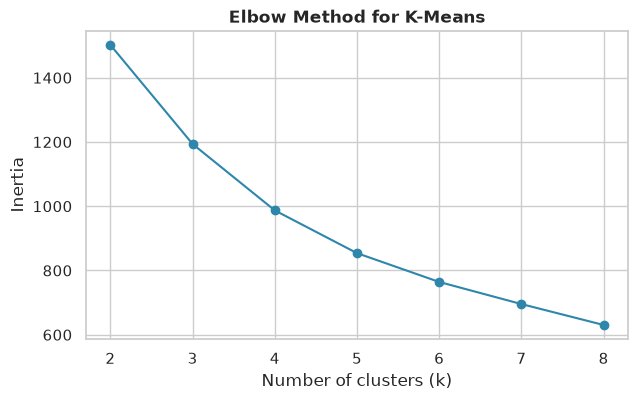

In [23]:
ref_date = df["Order Date"].max() + pd.Timedelta(days=1)
rfm = df.groupby("Customer ID").agg(Recency=("Order Date", lambda s: (ref_date - s.max()).days),
                                    Frequency=("Order ID", "nunique"),
                                    Monetary=("Sales", "sum"),
                                    Profit=("Profit", "sum"))
rfm_scaled = StandardScaler().fit_transform(np.log1p(rfm[["Recency", "Frequency", "Monetary"]]))

# Elbow method to choose k
inertia = {k: KMeans(n_clusters=k, n_init=10, random_state=42).fit(rfm_scaled).inertia_ for k in range(2, 9)}
plt.figure(figsize=(7, 4))
plt.plot(list(inertia), list(inertia.values()), marker="o", color=PAL[0])
plt.title("Elbow Method for K-Means"); plt.xlabel("Number of clusters (k)"); plt.ylabel("Inertia")
plt.show()

In [24]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(rfm_scaled)
rfm["Cluster"] = km.labels_

profile = rfm.groupby("Cluster").agg(Customers=("Recency", "size"), Recency=("Recency", "mean"),
                                     Frequency=("Frequency", "mean"), Monetary=("Monetary", "mean"),
                                     Profit=("Profit", "mean"))
# Name clusters by average spend (highest spend = Champions)
order = profile["Monetary"].rank(ascending=False).astype(int)
labels = {1: "Champions", 2: "Loyal", 3: "Potential", 4: "Low Value"}
profile["Segment Name"] = order.map(labels)
rfm["Segment Name"] = rfm["Cluster"].map(profile["Segment Name"])
profile.sort_values("Monetary", ascending=False)

,Customers,Recency,Frequency,Monetary,Profit,Segment Name
Cluster,,,,,,
0,249,95.57,8.89,"4,886.80",663.20,Champions
3,202,19.54,6.79,"2,683.17",355.48,Loyal
2,262,235.70,4.97,"2,020.68",203.52,Potential
1,91,315.43,2.54,416.70,22.06,Low Value


### 4.6 Forecasting – Monthly sales
Monthly sales are split **chronologically**: all months except the last 12 are used for training, the last 12 for testing.
* **Seasonal naive** baseline: sales of the same month in the previous year.
* **Linear regression** with a trend term + month-of-year dummies.

In [25]:
monthly = df.set_index("Order Date").resample("MS")["Sales"].sum().to_frame("Sales")
monthly["t"] = np.arange(len(monthly))
monthly["m"] = monthly.index.month
Xm = pd.get_dummies(monthly[["t", "m"]], columns=["m"], drop_first=True).astype(float)

train, test = monthly.iloc[:-12], monthly.iloc[-12:]
lr_ts = LinearRegression().fit(Xm.iloc[:-12], train["Sales"])
test = test.assign(**{"Linear Regression": lr_ts.predict(Xm.iloc[-12:]),
                      "Seasonal Naive": monthly["Sales"].shift(12).iloc[-12:]})

fc_results = pd.DataFrame({m: {"MAE ($)": mean_absolute_error(test["Sales"], test[m]),
                               "RMSE ($)": np.sqrt(mean_squared_error(test["Sales"], test[m])),
                               "MAPE (%)": np.mean(np.abs((test["Sales"] - test[m]) / test["Sales"])) * 100}
                           for m in ["Seasonal Naive", "Linear Regression"]}).T
fc_results

,MAE ($),RMSE ($),MAPE (%)
Seasonal Naive,"15,793.23","19,440.50",24.44
Linear Regression,"11,379.46","15,640.45",17.56


In [26]:
# Forecast for the next 6 months (model refit on all data)
lr_full = LinearRegression().fit(Xm, monthly["Sales"])
future_idx = pd.date_range(monthly.index[-1] + pd.offsets.MonthBegin(), periods=6, freq="MS")
fut = pd.DataFrame({"t": np.arange(len(monthly), len(monthly) + 6), "m": future_idx.month}, index=future_idx)
Xf = pd.get_dummies(fut, columns=["m"]).reindex(columns=Xm.columns, fill_value=0).astype(float)
future = pd.Series(lr_full.predict(Xf), index=future_idx, name="Forecast Sales ($)")
future.to_frame()

,Forecast Sales ($)
2027-01-01,"42,697.88"
2027-02-01,"33,618.31"
2027-03-01,"71,348.52"
2027-04-01,"53,134.84"
2027-05-01,"58,371.76"
2027-06-01,"57,045.50"


## 5. Results

In [27]:
k = kpis(df)
cat = perf("Category"); reg = perf("Region"); sub = perf("Sub-Category")
band = df.groupby("Discount Band", observed=True).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
band["Margin %"] = band["Profit"] / band["Sales"] * 100
best_month = monthly["Sales"].idxmax()

print("KEY FINDINGS")
print("-" * 60)
print(f"Total sales ${k['Total Sales ($)']:,.0f}, profit ${k['Total Profit ($)']:,.0f}, margin {k['Profit Margin (%)']:.1f}%")
print(f"Orders: {k['Orders']:,}, customers: {k['Customers']:,}, AOV ${k['Avg Order Value ($)']:,.0f}")
print(f"Highest-sales category : {cat['Sales'].idxmax()} (${cat['Sales'].max():,.0f})")
print(f"Most profitable category: {cat['Profit'].idxmax()} (margin {cat.loc[cat['Profit'].idxmax(), 'Margin %']:.1f}%)")
print(f"Most profitable region : {reg['Profit'].idxmax()} | least: {reg['Profit'].idxmin()}")
print(f"Loss-making sub-categories: {', '.join(sub[sub['Profit'] < 0].index)}")
print(f"Loss-making products: {len(loss_products)}")
print(f"Best sales month: {best_month:%B %Y} (${monthly['Sales'].max():,.0f})")
print(f"Margin by discount band: " + ", ".join(f"{b}: {m:.1f}%" for b, m in band['Margin %'].items()))
rr = return_rate("Region")
print(f"Return rate: {k['Return Rate (% of orders)']:.1f}% of orders | highest region: {rr.index[0]} "
      f"({rr['Return Rate %'].iloc[0]:.1f}% of lines), lowest: {rr.index[-1]} ({rr['Return Rate %'].iloc[-1]:.1f}%)")
print()
print("MODEL PERFORMANCE")
print("-" * 60)
display(reg_results.round(3))
display(clf_results.round(3))
display(fc_results.round(1))

KEY FINDINGS
------------------------------------------------------------
Total sales $2,326,154, profit $292,273, margin 12.6%
Orders: 5,111, customers: 804, AOV $455
Highest-sales category : Technology ($839,893)
Most profitable category: Technology (margin 17.4%)
Most profitable region : West | least: Central
Loss-making sub-categories: Tables, Bookcases, Supplies
Loss-making products: 302
Best sales month: November 2026 ($118,455)
Margin by discount band: No discount: 29.6%, 1-20%: 11.9%, 21-40%: -15.3%, 41-80%: -77.4%
Return rate: 5.8% of orders | highest region: West (15.1% of lines), lowest: Central (3.9%)

MODEL PERFORMANCE
------------------------------------------------------------


,R2 (test),R2 (5-fold CV),MAE ($),RMSE ($)
Model,,,,
Linear Regression,0.80,0.62,35.45,103.63
Random Forest,0.67,0.59,19.54,131.38


,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.94,0.94,0.72,0.82
Decision Tree,0.95,0.96,0.76,0.85


,MAE ($),RMSE ($),MAPE (%)
Seasonal Naive,"15,793.20","19,440.50",24.40
Linear Regression,"11,379.50","15,640.50",17.60


## 6. Visualization (Charts / Plots)

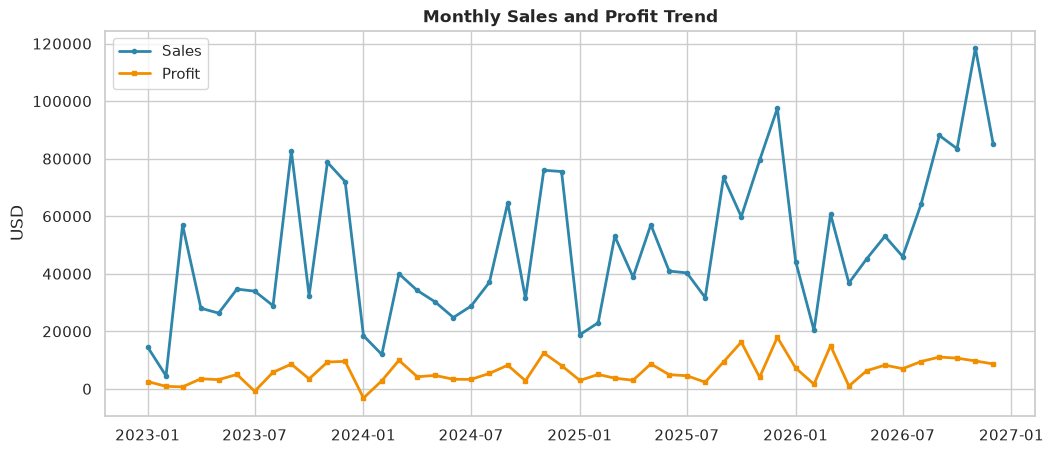

In [28]:
# 6.1 Monthly sales and profit trend (line chart)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly.index, monthly["Sales"], color=PAL[0], marker="o", ms=3, lw=2, label="Sales")
ax.plot(monthly.index, df.set_index("Order Date").resample("MS")["Profit"].sum(),
        color=PAL[1], marker="s", ms=3, lw=2, label="Profit")
ax.set_title("Monthly Sales and Profit Trend"); ax.set_ylabel("USD"); ax.legend()
plt.show()

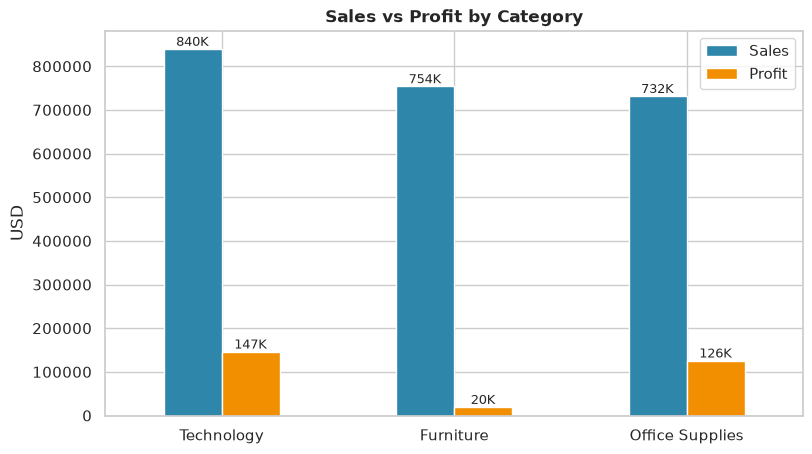

In [29]:
# 6.2 Sales and profit by category (grouped bar chart)
c = perf("Category")[["Sales", "Profit"]]
ax = c.plot(kind="bar", color=[PAL[0], PAL[1]], rot=0, figsize=(9, 5))
ax.set_title("Sales vs Profit by Category"); ax.set_ylabel("USD"); ax.set_xlabel("")
for p in ax.patches:
    ax.annotate(f"{p.get_height()/1000:,.0f}K", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
plt.show()

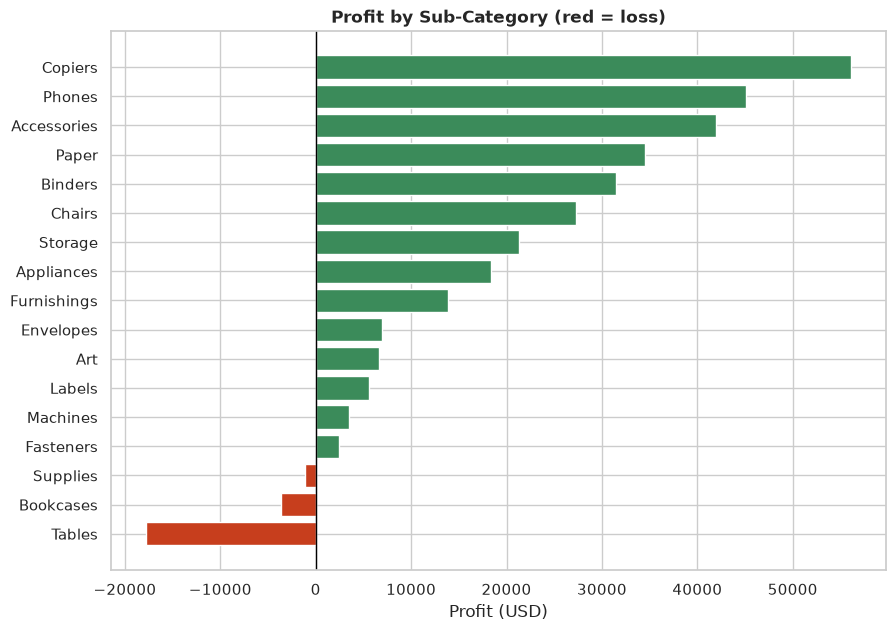

In [30]:
# 6.3 Profit by sub-category (positive vs negative bars)
s = perf("Sub-Category")["Profit"].sort_values()
plt.figure(figsize=(10, 7))
plt.barh(s.index, s.values, color=[NEG if v < 0 else POS for v in s.values])
plt.axvline(0, color="black", lw=1)
plt.title("Profit by Sub-Category (red = loss)"); plt.xlabel("Profit (USD)")
plt.show()

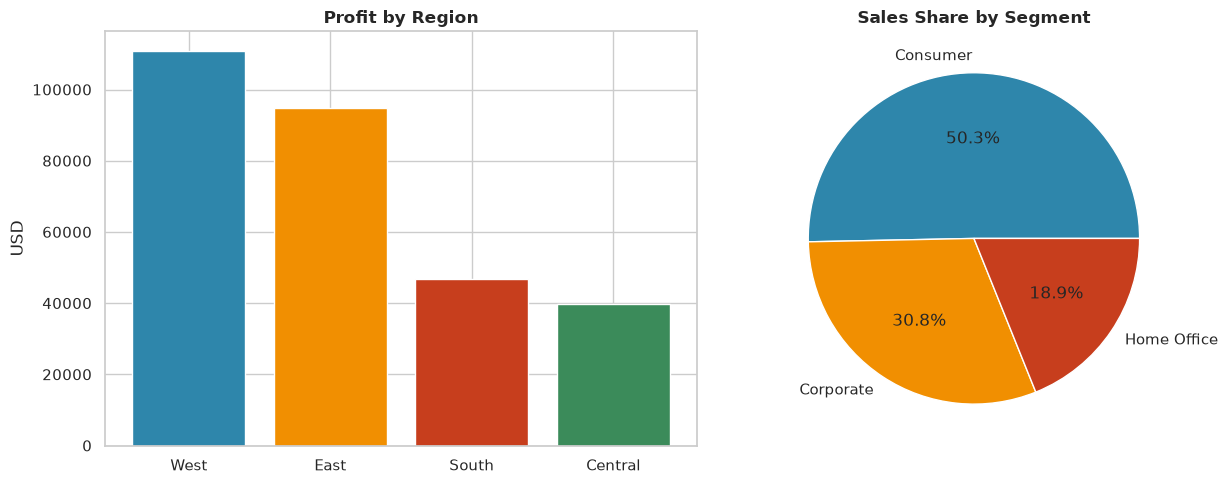

In [31]:
# 6.4 Profit by region (bar) and sales share by segment (pie)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
r = perf("Region")["Profit"].sort_values(ascending=False)
axes[0].bar(r.index, r.values, color=PAL[:4]); axes[0].set_title("Profit by Region"); axes[0].set_ylabel("USD")
seg = df.groupby("Segment")["Sales"].sum()
axes[1].pie(seg, labels=seg.index, autopct="%1.1f%%", colors=PAL[:3], wedgeprops={"edgecolor": "white"})
axes[1].set_title("Sales Share by Segment")
plt.tight_layout(); plt.show()

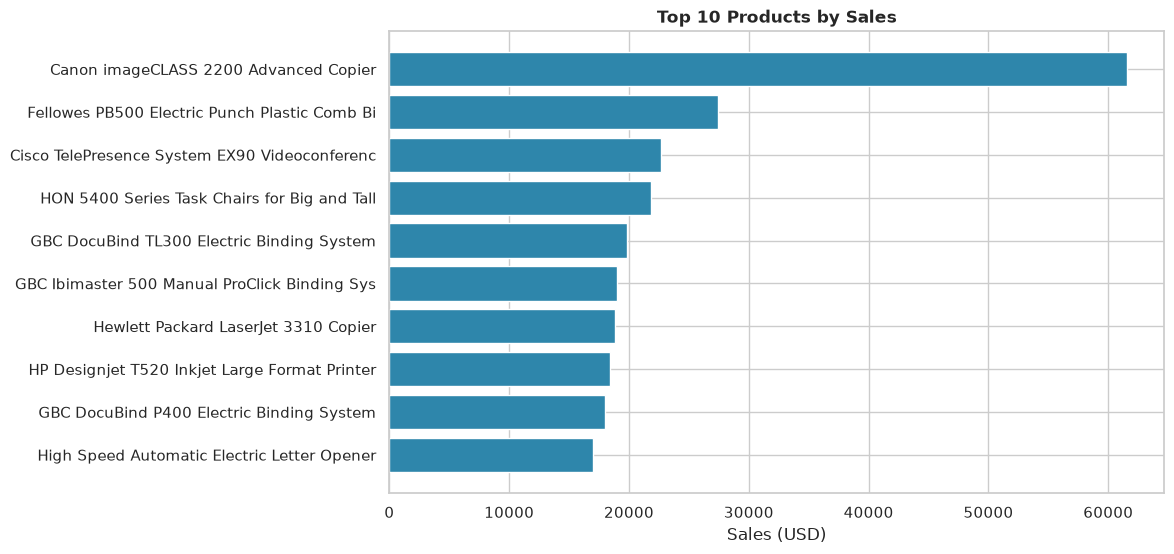

In [32]:
# 6.5 Top 10 products by sales
top = df.groupby("Product Name")["Sales"].sum().nlargest(10).sort_values()
plt.figure(figsize=(10, 6))
plt.barh([n[:45] for n in top.index], top.values, color=PAL[0])
plt.title("Top 10 Products by Sales"); plt.xlabel("Sales (USD)")
plt.show()

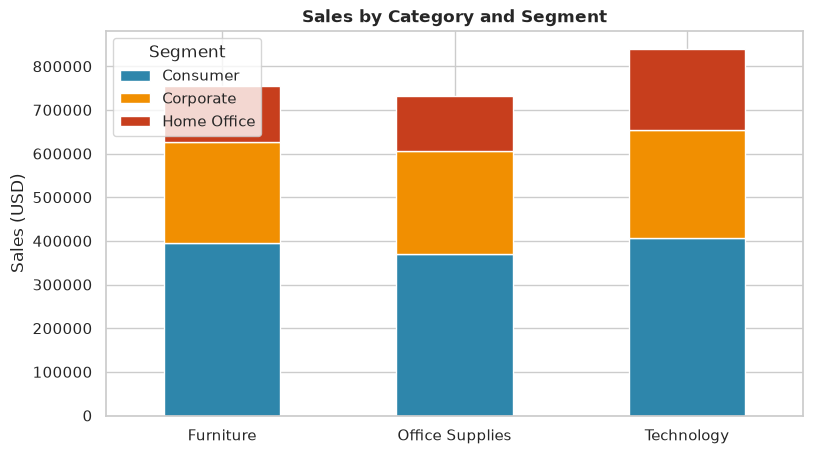

In [33]:
# 6.6 Sales by category and segment (stacked bar)
pv = df.pivot_table(index="Category", columns="Segment", values="Sales", aggfunc="sum")
ax = pv.plot(kind="bar", stacked=True, color=PAL[:3], rot=0, figsize=(9, 5))
ax.set_title("Sales by Category and Segment"); ax.set_ylabel("Sales (USD)"); ax.set_xlabel("")
plt.show()

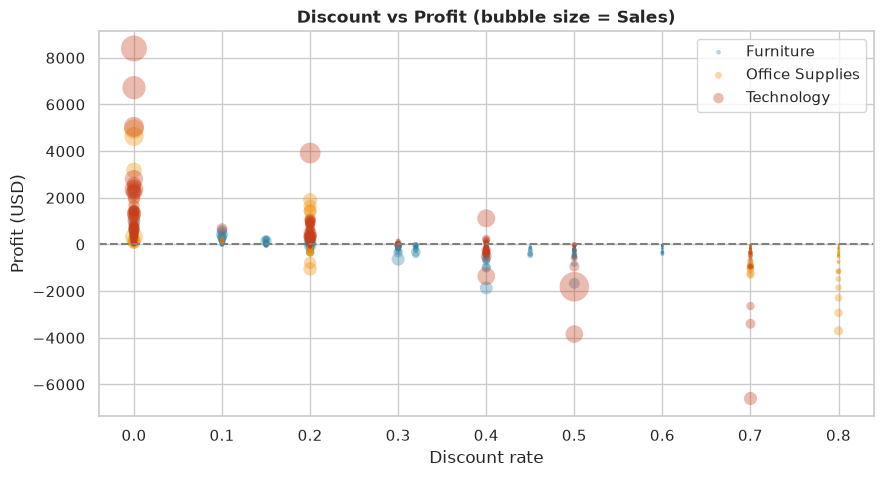

Correlation(Discount, Profit) = -0.219 -> association only, not proof of causation


In [34]:
# 6.7 Discount vs profit (scatter, size = sales)
plt.figure(figsize=(10, 5))
for i, (cat, g) in enumerate(df.groupby("Category")):
    plt.scatter(g["Discount"], g["Profit"], s=g["Sales"] / 50, color=PAL[i], alpha=0.35, edgecolors="none", label=cat)
plt.axhline(0, color="grey", ls="--"); plt.legend(markerscale=0.5)
plt.title("Discount vs Profit (bubble size = Sales)"); plt.xlabel("Discount rate"); plt.ylabel("Profit (USD)")
plt.show()
print("Correlation(Discount, Profit) =", round(df["Discount"].corr(df["Profit"]), 3),
      "-> association only, not proof of causation")

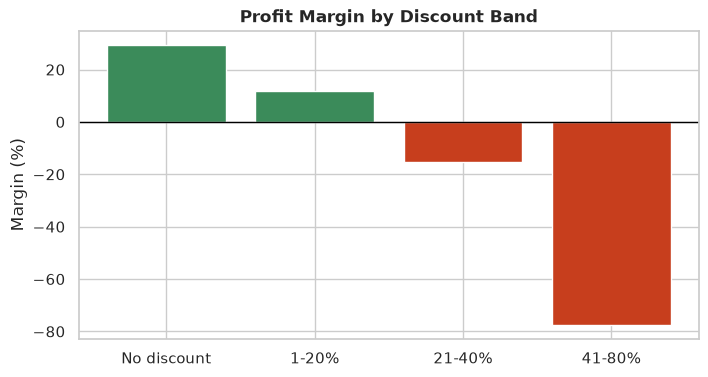

In [35]:
# 6.8 Profit margin by discount band (bar)
plt.figure(figsize=(8, 4))
plt.bar(band.index.astype(str), band["Margin %"], color=[POS if v >= 0 else NEG for v in band["Margin %"]])
plt.axhline(0, color="black", lw=1)
plt.title("Profit Margin by Discount Band"); plt.ylabel("Margin (%)")
plt.show()

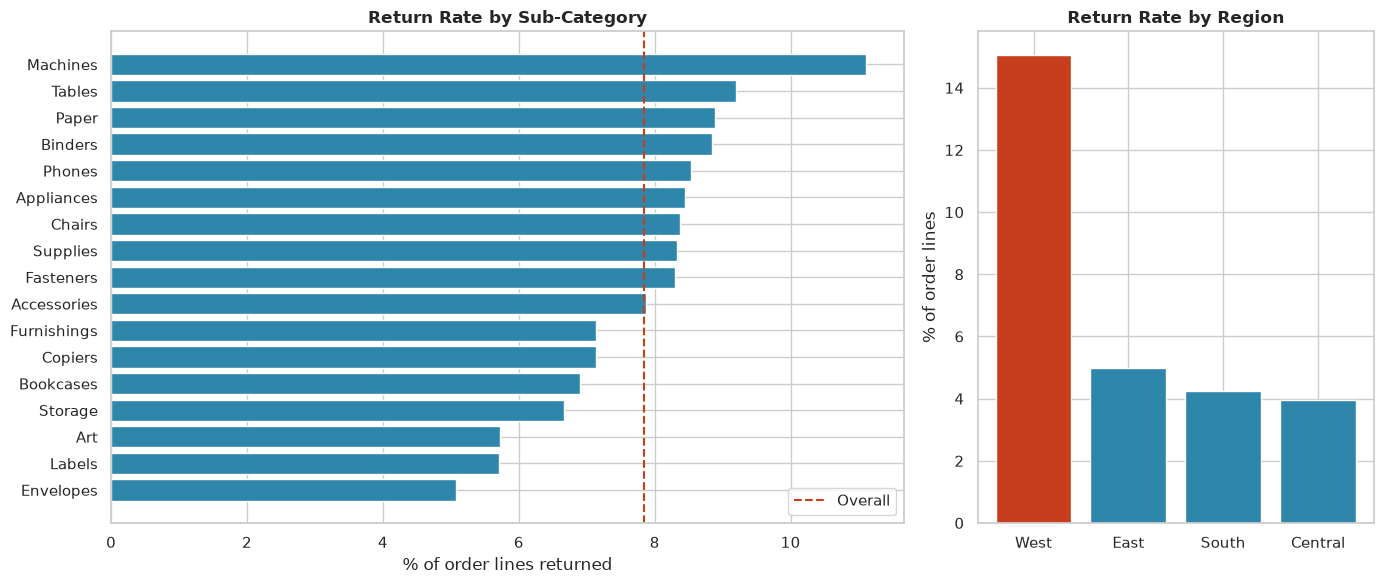

In [36]:
# 6.9 Return rate by sub-category and by region
fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [2, 1]})
rs = return_rate("Sub-Category")["Return Rate %"].sort_values()
axes[0].barh(rs.index, rs.values, color=PAL[0])
axes[0].axvline(df["Is Returned"].mean() * 100, color=PAL[2], ls="--", label="Overall")
axes[0].set_title("Return Rate by Sub-Category"); axes[0].set_xlabel("% of order lines returned"); axes[0].legend()
rr = return_rate("Region")["Return Rate %"]
axes[1].bar(rr.index, rr.values, color=[PAL[2]] + [PAL[0]] * 3)
axes[1].set_title("Return Rate by Region"); axes[1].set_ylabel("% of order lines")
plt.tight_layout(); plt.show()

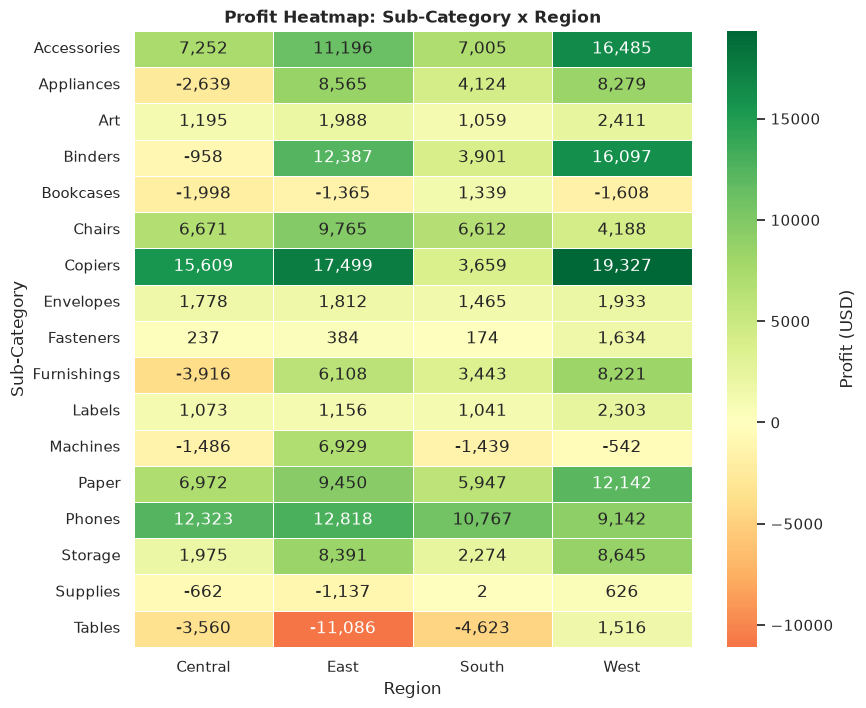

In [37]:
# 6.10 Heatmap: profit by sub-category and region
hm = df.pivot_table(index="Sub-Category", columns="Region", values="Profit", aggfunc="sum")
plt.figure(figsize=(9, 8))
sns.heatmap(hm, cmap="RdYlGn", center=0, annot=True, fmt=",.0f", linewidths=0.5, linecolor="white", cbar_kws={"label": "Profit (USD)"})
plt.title("Profit Heatmap: Sub-Category x Region")
plt.show()

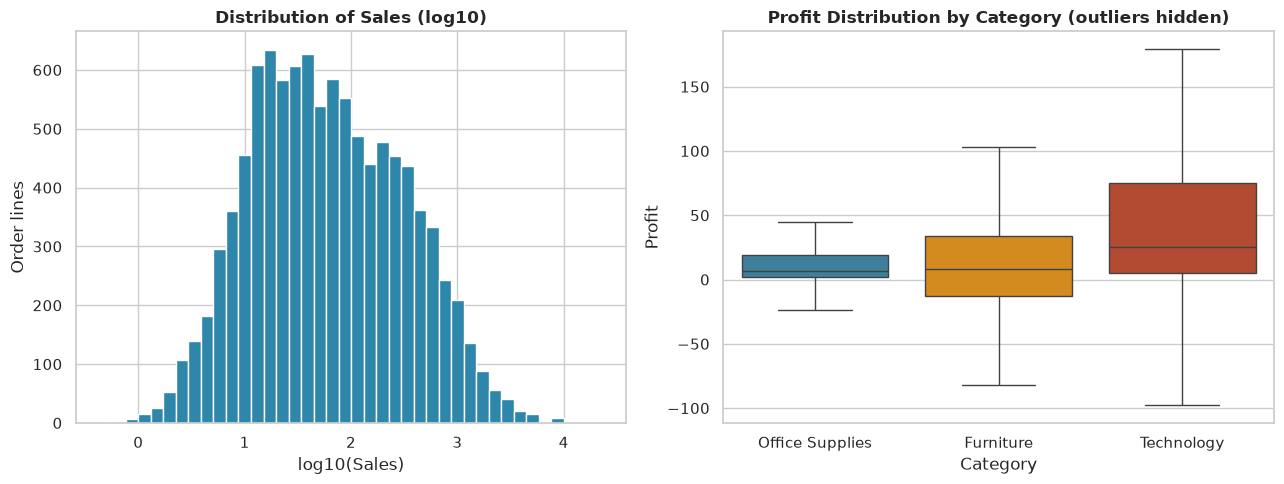

In [38]:
# 6.11 Distribution of sales (histogram, log scale) and profit by category (box plot)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(np.log10(df["Sales"]), bins=40, color=PAL[0], edgecolor="white")
axes[0].set_title("Distribution of Sales (log10)"); axes[0].set_xlabel("log10(Sales)"); axes[0].set_ylabel("Order lines")
sns.boxplot(data=df, x="Category", y="Profit", hue="Category", palette=PAL[:3], legend=False, ax=axes[1], showfliers=False)
axes[1].set_title("Profit Distribution by Category (outliers hidden)")
plt.tight_layout(); plt.show()

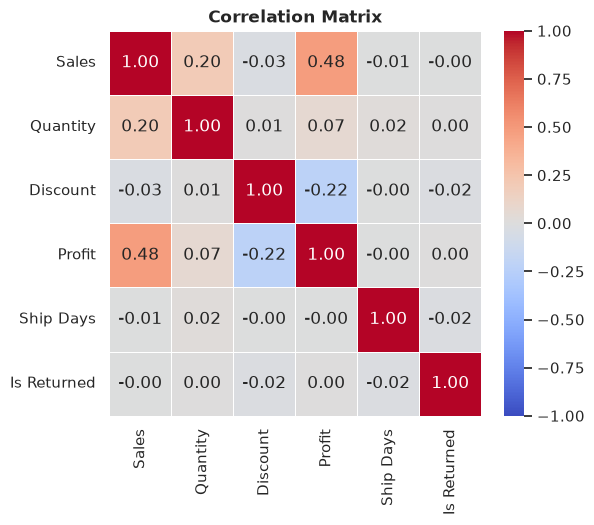

In [39]:
# 6.12 Correlation heatmap of numeric fields
plt.figure(figsize=(6, 5))
sns.heatmap(df[["Sales", "Quantity", "Discount", "Profit", "Ship Days", "Is Returned"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix")
plt.show()

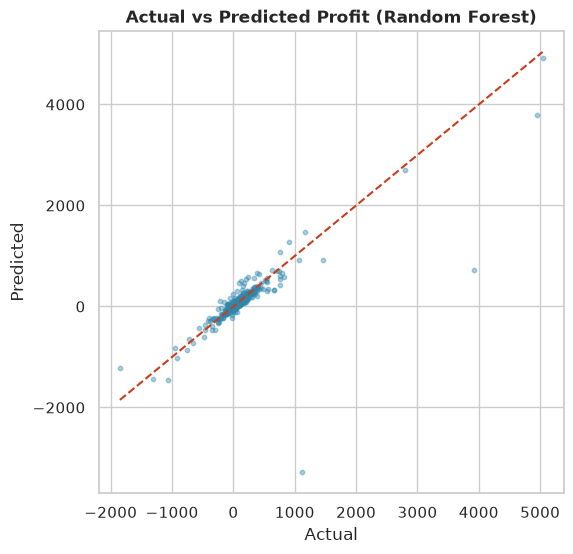

In [40]:
# 6.13 Regression: actual vs predicted profit (Random Forest)
yte_reg = y_reg.loc[train_test_split(X, y_reg, test_size=0.2, random_state=42)[1].index]
plt.figure(figsize=(6, 6))
plt.scatter(yte_reg, reg_preds["Random Forest"], s=10, color=PAL[0], alpha=0.4)
lim = [yte_reg.min(), yte_reg.max()]
plt.plot(lim, lim, color=PAL[2], ls="--")
plt.title("Actual vs Predicted Profit (Random Forest)"); plt.xlabel("Actual"); plt.ylabel("Predicted")
plt.show()

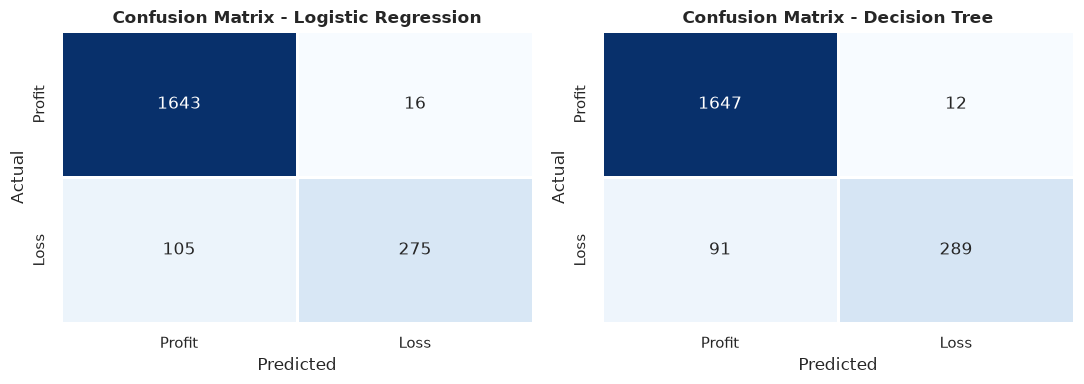

In [41]:
# 6.14 Classification: confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, clf_preds):
    sns.heatmap(confusion_matrix(yte, clf_preds[name]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Profit", "Loss"], yticklabels=["Profit", "Loss"], linewidths=1, linecolor="white")
    ax.set_title(f"Confusion Matrix - {name}"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

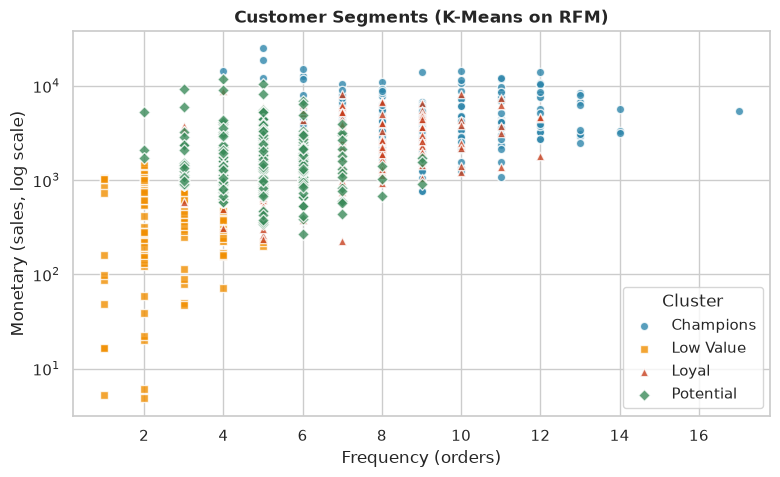

In [42]:
# 6.15 Customer clusters (RFM)
markers = ["o", "s", "^", "D"]
shades = PAL[:4]
plt.figure(figsize=(9, 5))
for i, (name, g) in enumerate(rfm.groupby("Segment Name")):
    plt.scatter(g["Frequency"], g["Monetary"], marker=markers[i], color=shades[i], edgecolor="white", label=name, alpha=0.8)
plt.yscale("log"); plt.legend(title="Cluster")
plt.title("Customer Segments (K-Means on RFM)"); plt.xlabel("Frequency (orders)"); plt.ylabel("Monetary (sales, log scale)")
plt.show()

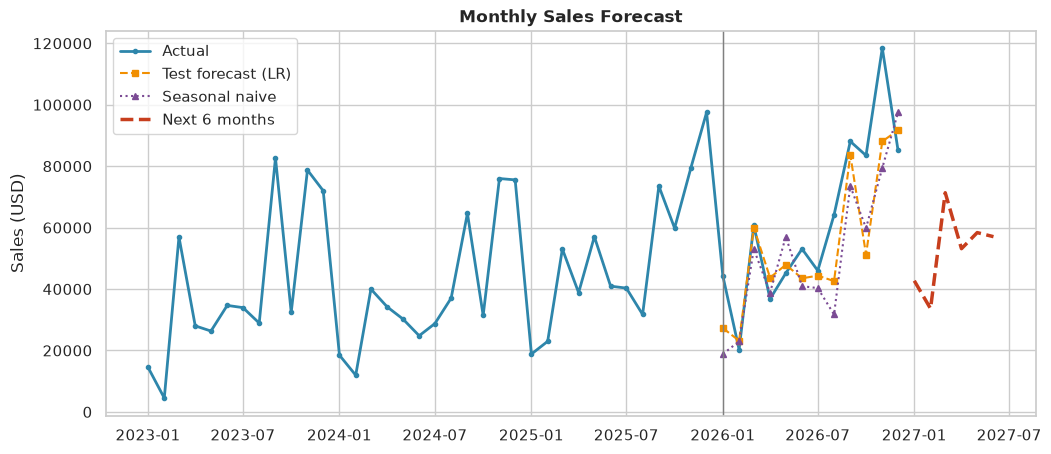

In [43]:
# 6.16 Forecast: actual vs predicted monthly sales + next 6 months
plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly["Sales"], color=PAL[0], marker="o", ms=3, lw=2, label="Actual")
plt.plot(test.index, test["Linear Regression"], color=PAL[1], ls="--", marker="s", ms=4, label="Test forecast (LR)")
plt.plot(test.index, test["Seasonal Naive"], color=PAL[4], ls=":", marker="^", ms=4, label="Seasonal naive")
plt.plot(future.index, future.values, color=PAL[2], ls="--", lw=2.5, label="Next 6 months")
plt.axvline(test.index[0], color="grey", lw=1)
plt.title("Monthly Sales Forecast"); plt.ylabel("Sales (USD)"); plt.legend()
plt.show()

## 7. Conclusion

* The full BI workflow — data collection, cleaning, integration of three sheets, analytics, mining models and visualization — was implemented on the official Superstore workbook (10,192 clean order lines, 2023–2026).
* **Technology** generates the most profit, while **Furniture** sells well but has a very thin margin; **Tables, Bookcases and Supplies** lose money overall.
* **Higher discounts are strongly associated with losses**: lines with discounts above 20% have negative margins on average. (This is an association in sample data, not proof that discounts cause losses.)
* The **West** and **East** regions are the most profitable; **Central** has the lowest profit.
* Sales grow year on year and show clear seasonality, peaking in **November–December** (and September).
* **Returns:** 5.8% of orders are returned. The **West** region (manager Sadie Pawthorne) has a return rate about three times higher than the other regions (15% of order lines vs 4–5%). Return rates are similar across categories, and discounted lines are *not* returned more often.
* **Regression:** with the discount-amount feature, Linear Regression explains about 62% of profit variation (5-fold CV R²) and is slightly better than Random Forest; a few extreme orders make single-split scores unstable.
* **Classification:** a shallow Decision Tree predicts loss-making lines with about 95% accuracy (precision 0.96, F1 0.85 for the loss class), slightly ahead of Logistic Regression.
* **Clustering:** RFM + K-Means groups customers into Champions, Loyal, Potential and Low Value segments for targeted action.
* **Forecasting:** a trend + seasonality regression beats the seasonal-naive baseline on the last 12 months.

**Recommendations:** cap discounts above ~20% (especially on Tables, Bookcases and Supplies), review pricing for loss-making products,
focus retention on Champion/Loyal customers, investigate why West-region orders are returned so often, and stock up for the Q4 peak.

**Limitations:** fictitious sample data; 200 Canada rows are mixed into the US regions; returns are recorded per order, not per product;
no cost, inventory, marketing or demographic fields; only four years of history for forecasting.

The interactive dashboard is in `app.py` — run `streamlit run app.py`.